# 1. General Preprocessing Module

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder

class TabularPreprocessor:
    def __init__(self):
        self.cont_cols = []
        self.cat_cols = []
        self.scaler = None
        self.label_encoders = {}
        self.metadata = []

    def fit_transform(self, df):
        df = df.copy()

        for col in df.columns:
            if df[col].dtype in ['int64', 'float64']:
                self.cont_cols.append(col)
                self.metadata.append(("continuous", col))
            else:
                self.cat_cols.append(col)
                self.metadata.append(("categorical", col))

        # Fill missing
        for col in self.cont_cols:
            df[col] = df[col].fillna(df[col].mean())

        for col in self.cat_cols:
            df[col] = df[col].fillna("MISSING")

        # Scale continuous
        self.scaler = StandardScaler()
        df[self.cont_cols] = self.scaler.fit_transform(df[self.cont_cols])

        # Encode categorical
        for col in self.cat_cols:
            le = LabelEncoder()
            df[col] = le.fit_transform(df[col])
            self.label_encoders[col] = le

        return df

    def get_metadata(self, df):
        meta = []
        for col in df.columns:
            if col in self.cont_cols:
                meta.append({
                    "type": "continuous",
                    "dim": 1
                })
            else:
                n_classes = len(self.label_encoders[col].classes_)
                meta.append({
                    "type": "categorical",
                    "dim": n_classes
                })
        return meta

    def inverse_transform(self, synthetic_array, original_columns):
      df_syn = pd.DataFrame(synthetic_array, columns=original_columns)

      # Inverse scale continuous
      df_syn[self.cont_cols] = self.scaler.inverse_transform(
          df_syn[self.cont_cols]
      )

      # Decode categorical
      for col in self.cat_cols:
          le = self.label_encoders[col]
          df_syn[col] = df_syn[col].astype(int)
          df_syn[col] = le.inverse_transform(df_syn[col])

      return df_syn


# 2. Graph-Conditioned Generator

In [ ]:
import numpy as np
import torch
import dcor

def build_dependency_graph(data, threshold=0.1):
    """
    Build adjacency matrix using distance correlation.
    Captures nonlinear dependencies.
    """

    n_features = data.shape[1]
    adj = np.zeros((n_features, n_features))

    # Compute pairwise distance correlation
    for i in range(n_features):
        for j in range(i, n_features):
            if i == j:
                adj[i, j] = 1.0
            else:
                dc = dcor.distance_correlation(
                    data[:, i],
                    data[:, j]
                )
                adj[i, j] = dc
                adj[j, i] = dc  # ensure symmetry

    # Threshold to sparsify
    adj = (adj > threshold).astype(float)

    # Degree normalization
    D = np.diag(np.sum(adj, axis=1))
    D_inv_sqrt = np.linalg.inv(np.sqrt(D + 1e-8))
    adj_norm = D_inv_sqrt @ adj @ D_inv_sqrt

    return torch.tensor(adj_norm, dtype=torch.float32)


# 3. Generator + Discriminator

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class TypeAwareGraphGenerator(nn.Module):
    def __init__(self, metadata, latent_dim=64, hidden_dim=256):
        super().__init__()

        self.metadata = metadata
        self.num_features = len(metadata)

        self.feature_embedding = nn.Parameter(
            torch.randn(self.num_features, hidden_dim)
        )

        self.latent_proj = nn.Linear(latent_dim, hidden_dim)

        self.gnn1 = nn.Linear(hidden_dim, hidden_dim)
        self.gnn2 = nn.Linear(hidden_dim, hidden_dim)

        # Per-feature output heads
        self.output_heads = nn.ModuleList()

        for info in metadata:
            if info["type"] == "continuous":
                self.output_heads.append(
                    nn.Sequential(
                        nn.Linear(hidden_dim, hidden_dim),
                        nn.ReLU(),
                        nn.Linear(hidden_dim, 1)
                    )
                )
            else:
                self.output_heads.append(
                    nn.Sequential(
                        nn.Linear(hidden_dim, hidden_dim),
                        nn.ReLU(),
                        nn.Linear(hidden_dim, info["dim"])
                    )
                )

    def forward(self, z, adj, tau=0.5):
        batch_size = z.size(0)

        global_context = self.latent_proj(z)

        h = self.feature_embedding.unsqueeze(0).repeat(batch_size, 1, 1)
        h = h + global_context.unsqueeze(1)

        h = h + torch.matmul(adj, h)
        h = F.relu(self.gnn1(h))

        h = h + torch.matmul(adj, h)
        h = F.relu(self.gnn2(h))

        outputs = []

        for i, head in enumerate(self.output_heads):
            node_repr = h[:, i, :]
            out = head(node_repr)

            if self.metadata[i]["type"] == "categorical":
                out = F.gumbel_softmax(out, tau=tau, hard=True)

            outputs.append(out)

        return torch.cat(outputs, dim=1)
class Discriminator(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.model(x)

def gradient_penalty(D, real, fake):
    device = real.device
    alpha = torch.rand(real.size(0), 1, device=device)
    interpolates = alpha * real + (1 - alpha) * fake
    interpolates.requires_grad_(True)

    d_interpolates = D(interpolates)

    grads = torch.autograd.grad(
        outputs=d_interpolates,
        inputs=interpolates,
        grad_outputs=torch.ones_like(d_interpolates),
        create_graph=True,
        retain_graph=True,
        only_inputs=True
    )[0]

    return ((grads.norm(2, dim=1) - 1) ** 2).mean()

import torch.nn.functional as F

def transform_real_to_model_space(data, metadata):
    transformed = []
    col_idx = 0

    for info in metadata:
        if info["type"] == "continuous":
            transformed.append(data[:, col_idx:col_idx+1])
            col_idx += 1
        else:
            num_classes = info["dim"]
            cat_vals = data[:, col_idx].long()
            one_hot = F.one_hot(cat_vals, num_classes=num_classes).float()
            transformed.append(one_hot)
            col_idx += 1

    return torch.cat(transformed, dim=1)



# 4. Training Loop

In [ ]:
import torch.optim as optim

def train_gctg(generator, discriminator, data, adj, epochs=300):

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    generator.to(device)
    discriminator.to(device)
    adj = adj.to(device)

    data = torch.tensor(data, dtype=torch.float32).to(device)
    data = transform_real_to_model_space(data, generator.metadata)


    real_mean = data.mean(dim=0)
    real_std = data.std(dim=0)

    g_opt = optim.Adam(generator.parameters(), lr=1e-4, betas=(0.5, 0.9))
    d_opt = optim.Adam(discriminator.parameters(), lr=5e-5, betas=(0.5, 0.9))

    latent_dim = 64
    batch_size = 64
    lambda_gp = 10
    lambda_stats = 5

    for epoch in range(epochs):

        for i in range(0, len(data), batch_size):

            real = data[i:i+batch_size]

            # Train D
            for _ in range(5):
                z = torch.randn(real.size(0), latent_dim, device=device)
                fake = generator(z, adj)

                gp = gradient_penalty(discriminator, real, fake)

                d_loss = -(torch.mean(discriminator(real)) -
                           torch.mean(discriminator(fake.detach()))) \
                         + lambda_gp * gp

                d_opt.zero_grad()
                d_loss.backward()
                d_opt.step()

            # Train G
            z = torch.randn(real.size(0), latent_dim, device=device)
            fake = generator(z, adj)

            fake_mean = fake.mean(dim=0)
            fake_std = fake.std(dim=0)

            stat_loss = torch.mean((fake_mean - real_mean) ** 2) + \
                        torch.mean((fake_std - real_std) ** 2)

            g_loss = -torch.mean(discriminator(fake)) + \
                     lambda_stats * stat_loss

            g_opt.zero_grad()
            g_loss.backward()
            g_opt.step()

        if epoch % 20 == 0:
            print(f"Epoch {epoch} | D: {d_loss.item():.4f} | G: {g_loss.item():.4f}")
def collapse_model_to_node_space_numpy(fake, metadata):
    outputs = []
    idx = 0

    for info in metadata:
        if info["type"] == "continuous":
            outputs.append(fake[:, idx:idx+1])
            idx += 1
        else:
            dim = info["dim"]
            one_hot = fake[:, idx:idx+dim]
            values = np.argmax(one_hot, axis=1).reshape(-1, 1)
            outputs.append(values)
            idx += dim

    return np.concatenate(outputs, axis=1)



# 5. Statistical Validation

In [ ]:
from scipy.stats import ks_2samp

def ks_test(real, synthetic):
    scores = []
    for i in range(real.shape[1]):
        stat, _ = ks_2samp(real[:, i], synthetic[:, i])
        scores.append(stat)
    return np.mean(scores)




# 6. Correlation Similarity

In [ ]:
def correlation_diff(real, synthetic):
    corr_real = np.corrcoef(real.T)
    corr_syn = np.corrcoef(synthetic.T)
    return np.mean(np.abs(corr_real - corr_syn))

# 7. Final Pipeline

In [ ]:
import torch
df = pd.read_csv("cakut_dataset.csv")

if "Sl_No" in df.columns:
    df = df.drop(columns=["Sl_No"])

pre = TabularPreprocessor()
processed = pre.fit_transform(df)
metadata = pre.get_metadata(df)

adj = build_dependency_graph(processed.values)

gen = TypeAwareGraphGenerator(metadata)

expanded_dim = sum(info["dim"] for info in metadata)
disc = Discriminator(input_dim=expanded_dim)


train_gctg(gen, disc, processed.values, adj)

device = next(gen.parameters()).device
z = torch.randn(1000, 64, device=device)
synthetic_model = gen(z, adj.to(device)).detach().cpu().numpy()
synthetic = collapse_model_to_node_space_numpy(synthetic_model, metadata)



Epoch 0 | D: 7.7526 | G: 0.8894
Epoch 20 | D: 0.8699 | G: 0.0610
Epoch 40 | D: 0.7419 | G: 0.1449


In [ ]:
print("Synthetic std:", synthetic.std(axis=0))
print("Real std:", processed.values.std(axis=0))
print("Avg KS:", ks_test(processed.values, synthetic))
print("Correlation Diff:", correlation_diff(processed.values, synthetic))

Synthetic std: [0.97632153 0.97434286 0.45955522 0.72824172 0.49870232 0.80129832
 0.56602473 0.84805499 0.53246221 0.27187497]
Real std: [1.         0.93569268 0.48039012 0.68155353 0.49652774 0.88336277
 0.67890631 1.         0.57671798 0.32001805]
Avg KS: 0.09304117647058824
Correlation Diff: 0.06857724048217147


In [ ]:
synthetic_df = pre.inverse_transform(
    synthetic,
    original_columns=df.columns
)
synthetic_df.to_csv("synthetic_1000_records.csv", index=False)
device = next(gen.parameters()).device
z = torch.randn(1000, 64, device=device)

synthetic_model = gen(z, adj.to(device)).detach().cpu().numpy()

synthetic = collapse_model_to_node_space_numpy(
    synthetic_model,
    metadata
)

synthetic_df = pre.inverse_transform(
    synthetic,
    original_columns=df.columns
)

print(synthetic_df.head())


   Mother_Age   Age  Parity_Group Detection_Window Laterality_Class  \
0   25.314710    28  Multigravida              Mid       Unilateral   
1   28.046669    35  Multigravida            Early        Bilateral   
2   30.663498    28  Multigravida            Early        Bilateral   
3   31.585173    35  Multigravida              Mid       Unilateral   
4   21.771414  22.5  Multigravida              Mid        Bilateral   

           CAKUT_MAIN_CLASS      ANATOMY_GROUP  SEVERITY_CLASS  \
0  Pelvicalyceal_Dilatation  Collecting_System        0.857674   
1  Pelvicalyceal_Dilatation  Collecting_System        0.943832   
2  Pelvicalyceal_Dilatation  Collecting_System        0.983846   
3  Pelvicalyceal_Dilatation  Collecting_System        1.518207   
4         Obstructive_CAKUT           Lower_UT        2.491827   

  PROGRESSION_CLASS RENAL_THREAT_CLASS  
0               Low                Low  
1               Low                Low  
2               Low                Low  
3           

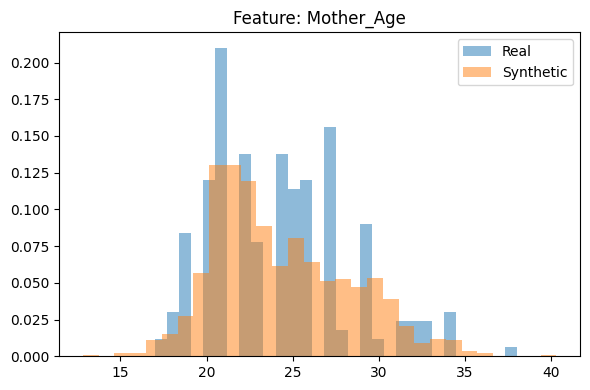

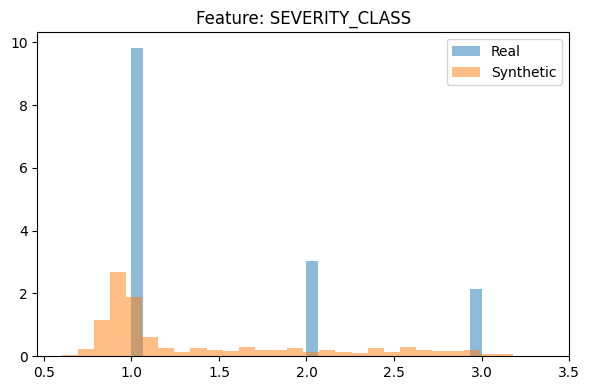

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
def plot_histograms(real, synthetic, metadata, feature_names=None):
    num_features = real.shape[1]

    for i in range(num_features):
        if metadata[i]["type"] == "continuous":

            plt.figure(figsize=(6,4))

            plt.hist(real[:, i], bins=30, alpha=0.5, label="Real", density=True)
            plt.hist(synthetic[:, i], bins=30, alpha=0.5, label="Synthetic", density=True)

            if feature_names is not None:
                plt.title(f"Feature: {feature_names[i]}")
            else:
                plt.title(f"Feature {i}")

            plt.legend()
            plt.tight_layout()
            plt.show()
plot_histograms(
    real=df.values,
    synthetic=synthetic_df.values,
    metadata=metadata,
    feature_names=df.columns
)

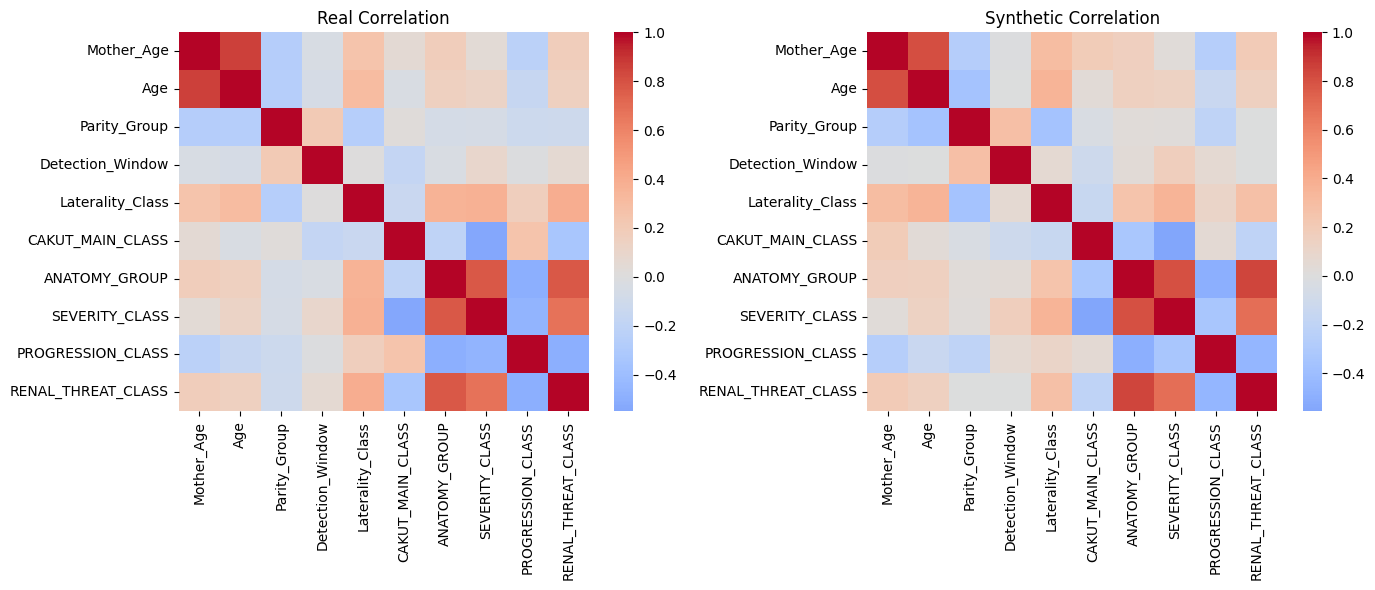

In [ ]:
def plot_correlation_heatmaps(real, synthetic, feature_names=None):

    corr_real = np.corrcoef(real.T)
    corr_syn = np.corrcoef(synthetic.T)

    fig, axes = plt.subplots(1, 2, figsize=(14,6))

    sns.heatmap(corr_real, ax=axes[0], cmap="coolwarm", center=0,
                xticklabels=feature_names, yticklabels=feature_names)
    axes[0].set_title("Real Correlation")

    sns.heatmap(corr_syn, ax=axes[1], cmap="coolwarm", center=0,
                xticklabels=feature_names, yticklabels=feature_names)
    axes[1].set_title("Synthetic Correlation")

    plt.tight_layout()
    plt.show()
plot_correlation_heatmaps(
    real=processed.values,
    synthetic=synthetic,
    feature_names=df.columns
)


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

def tstr_evaluation(real_node, synthetic_node, target_index):

    # Split real into train/test
    X_real = real_node[:, :]
    y_real = real_node[:, target_index]

    X_real = np.delete(X_real, target_index, axis=1)

    X_train_real, X_test_real, y_train_real, y_test_real = train_test_split(
        X_real, y_real, test_size=0.3, random_state=42
    )

    # Prepare synthetic
    X_syn = synthetic_node[:, :]
    y_syn = X_syn[:, target_index]
    X_syn = np.delete(X_syn, target_index, axis=1)

    # Train on synthetic
    clf = RandomForestClassifier(n_estimators=100, random_state=42)
    clf.fit(X_syn, y_syn)

    # Test on real
    preds = clf.predict(X_test_real)

    acc = accuracy_score(y_test_real, preds)

    print("TSTR Accuracy:", acc)
    print("\nClassification Report:\n")
    print(classification_report(y_test_real, preds))

    return acc
target_index = processed.shape[1] - 1

tstr_evaluation(
    real_node=processed.values,
    synthetic_node=synthetic,
    target_index=target_index
)



TSTR Accuracy: 1.0

Classification Report:

              precision    recall  f1-score   support

         1.0       1.00      1.00      1.00        64
         2.0       1.00      1.00      1.00         8

    accuracy                           1.00        72
   macro avg       1.00      1.00      1.00        72
weighted avg       1.00      1.00      1.00        72



1.0

In [ ]:
from sklearn.neighbors import NearestNeighbors

def nndr(real, synthetic):
    nn_real = NearestNeighbors(n_neighbors=2).fit(real)
    dist_real, _ = nn_real.kneighbors(real)

    nn_syn = NearestNeighbors(n_neighbors=1).fit(real)
    dist_syn, _ = nn_syn.kneighbors(synthetic)

    return dist_syn.mean() / dist_real[:,1].mean()


In [ ]:
nndr(
    processed.values,
    synthetic
)

np.float64(4.957365557046157)

In [ ]:
unique, counts = np.unique(synthetic[:, target_index], return_counts=True)
print(dict(zip(unique, counts)))


{np.float64(1.0): np.int64(896), np.float64(2.0): np.int64(104)}
